In [1]:
import pandas as pd
import numpy as np


# 1. Load the data
df = pd.read_csv('temporal_summary.csv')

# 2. Clean up column names by stripping hidden leading/trailing spaces
df.columns = df.columns.str.strip()

# Create a backup copy of the raw data
data = df.copy()

print("Data loaded! Here are the first 5 rows:")
display(df.head())

# Output the data types to ensure 'hour_of_day' is numeric
print("\nData Types:")
print(df.dtypes)


Data loaded! Here are the first 5 rows:


,aggregate_id,timestamp_hour,total_volume,month_of_year,day_of_week,hour_of_day,acuity_1,acuity_2,acuity_3,acuity_4,acuity_5,upload_id
0,1,2111-08-21 20:00:00,1,8,6,20,0,0,0,1,0,3
1,2,2112-09-30 01:00:00,1,9,6,1,0,1,0,0,0,3
2,3,2114-06-25 14:00:00,1,6,2,14,0,0,1,0,0,3
3,4,2115-05-08 18:00:00,1,5,4,18,0,0,1,0,0,3
4,5,2115-09-25 15:00:00,1,9,4,15,0,0,1,0,0,3



Data Types:
aggregate_id       int64
timestamp_hour    object
total_volume       int64
month_of_year      int64
day_of_week        int64
hour_of_day        int64
acuity_1           int64
acuity_2           int64
acuity_3           int64
acuity_4           int64
acuity_5           int64
upload_id          int64
dtype: object


In [2]:
# Force 'hour_of_day' to be numeric. 
# errors='coerce' turns any unparseable strings into NaN instead of crashing.
df['hour_of_day'] = pd.to_numeric(df['hour_of_day'], errors='coerce')

# Safely create the time_window column
df['time_window'] = df['hour_of_day'] // 4

# Group and aggregate as you originally did
df_binned = df.groupby(['upload_id', 'day_of_week', 'time_window'], as_index=False).agg({
    'total_volume': 'sum',
    'acuity_1': 'sum',
    'acuity_2': 'sum',
    'acuity_3': 'sum',
    'acuity_4': 'sum',
    'acuity_5': 'sum',
    'month_of_year': 'first'
})

print("Data Binned! Here is the new structure:")
display(df_binned.head(10))


Data Binned! Here is the new structure:


,upload_id,day_of_week,time_window,total_volume,acuity_1,acuity_2,acuity_3,acuity_4,acuity_5,month_of_year
0,3,1,0,2,0,2,0,0,0,8
1,3,1,1,2,0,0,2,0,0,9
2,3,1,2,2,0,1,0,1,0,6
3,3,1,3,2,0,1,1,0,0,11
4,3,1,4,5,0,2,2,1,0,9
5,3,1,5,4,0,3,1,0,0,9
6,3,2,2,5,0,2,3,0,0,6
7,3,2,3,5,0,0,4,1,0,6
8,3,2,4,4,0,0,3,1,0,3
9,3,2,5,2,0,0,1,1,0,11


In [4]:
df.describe()


,aggregate_id,total_volume,month_of_year,day_of_week,hour_of_day,acuity_1,acuity_2,acuity_3,acuity_4,acuity_5,upload_id
count,658.000000,658.0,658.000000,658.000000,658.000000,658.000000,658.000000,658.000000,658.000000,658.0,658.000000
mean,329.500000,1.0,6.802432,3.841945,13.370821,0.039514,0.319149,0.554711,0.086626,0.0,5.504559
std,190.092521,0.0,3.533772,1.946609,5.688184,0.194962,0.466501,0.497376,0.281500,0.0,1.694510
min,1.000000,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,3.000000
25%,165.250000,1.0,4.000000,2.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.0,4.000000
50%,329.500000,1.0,7.000000,4.000000,14.000000,0.000000,0.000000,1.000000,0.000000,0.0,6.000000
75%,493.750000,1.0,10.000000,5.000000,18.000000,0.000000,1.000000,1.000000,0.000000,0.0,7.000000
max,658.000000,1.0,12.000000,7.000000,23.000000,1.000000,1.000000,1.000000,1.000000,0.0,8.000000


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 658 entries, 0 to 657
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   aggregate_id    658 non-null    int64 
 1   timestamp_hour  658 non-null    object
 2   total_volume    658 non-null    int64 
 3   month_of_year   658 non-null    int64 
 4   day_of_week     658 non-null    int64 
 5   hour_of_day     658 non-null    int64 
 6   acuity_1        658 non-null    int64 
 7   acuity_2        658 non-null    int64 
 8   acuity_3        658 non-null    int64 
 9   acuity_4        658 non-null    int64 
 10  acuity_5        658 non-null    int64 
 11  upload_id       658 non-null    int64 
dtypes: int64(11), object(1)
memory usage: 61.8+ KB


In [19]:
!pip install "numpy<2.0.0"


   ---------------------------------------- 0.0/15.5 MB ? eta -:--:--
   ------------- -------------------------- 5.2/15.5 MB 29.0 MB/s eta 0:00:01
   ----------------------------- ---------- 11.5/15.5 MB 27.8 MB/s eta 0:00:01
   ---------------------------------------- 15.5/15.5 MB 25.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.1.3
    Uninstalling numpy-2.1.3:
      Successfully uninstalled numpy-2.1.3


  You can safely remove it manually.
  You can safely remove it manually.


In [3]:
# 1. We create a 'Window' column. 
# This divides the 24 hours of the day into 6 blocks (0, 1, 2, 3, 4, 5).
# Hour 0-3 = Block 0, Hour 4-7 = Block 1, etc.
data['time_window'] = data['hour_of_day'] // 4

# 2. Now we group by Upload, Day, and the new Window to sum up the volumes.
# This turns the "1s" into a "Total for that block".
data_binned = data.groupby(['upload_id', 'day_of_week', 'time_window']).agg({
    'total_volume': 'sum',
    'acuity_1': 'sum',
    'acuity_2': 'sum',
    'acuity_3': 'sum',
    'acuity_4': 'sum',
    'acuity_5': 'sum',
    'month_of_year': 'first' # Keep the month the same
}).reset_index()

print("Data Binned! Here is the new structure:")
display(data_binned.head(10))

Data Binned! Here is the new structure:


,upload_id,day_of_week,time_window,total_volume,acuity_1,acuity_2,acuity_3,acuity_4,acuity_5,month_of_year
0,3,1,0,2,0,2,0,0,0,8
1,3,1,1,2,0,0,2,0,0,9
2,3,1,2,2,0,1,0,1,0,6
3,3,1,3,2,0,1,1,0,0,11
4,3,1,4,5,0,2,2,1,0,9
5,3,1,5,4,0,3,1,0,0,9
6,3,2,2,5,0,2,3,0,0,6
7,3,2,3,5,0,0,4,1,0,6
8,3,2,4,4,0,0,3,1,0,3
9,3,2,5,2,0,0,1,1,0,11


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# # 1. Feature Selection
# categorical_features = ['day_of_week', 'time_window']
# numeric_features = ['month_of_year', 'acuity_1', 'acuity_2', 'acuity_3', 'acuity_4', 'acuity_5']

# # Notice we use `data_binned` based on your last snippet
# X = data_binned[categorical_features + numeric_features]
# y = data_binned['total_volume']

# 2. Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        # Handle unknown categories in case the API gets unexpected day/time inputs
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        # Scale numeric features (best practice for many algorithms)
        ('num', StandardScaler(), numeric_features)
    ]
)

# 3. Define Models to Evaluate
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Ridge Regression": Ridge()
}

# Create a 'previous_volume' column so the model has "memory"
data_binned['prev_volume'] = data_binned.groupby('upload_id')['total_volume'].shift(1)

# Do the same for acuity if you want to keep that detail
for i in range(1, 6):
    data_binned[f'prev_acuity_{i}'] = data_binned.groupby('upload_id')[f'acuity_{i}'].shift(1)

# Drop the first row of each upload because it won't have a "previous" value (NaN)
data_binned = data_binned.dropna()

# New Feature Selection
categorical_features = ['day_of_week', 'time_window']
# We use the PREVIOUS window's data as the input
numeric_features = ['month_of_year', 'prev_volume', 'prev_acuity_1', 'prev_acuity_2', 'prev_acuity_3', 'prev_acuity_4', 'prev_acuity_5']

X = data_binned[categorical_features + numeric_features]
y = data_binned['total_volume']

# 4. Train/Test Split (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model_name = None
best_pipeline = None
best_r2 = -float('inf')

print("--- Model Evaluation Results ---\n")

# 5. Training and Evaluation Loop
for name, model in models.items():
    # Combine preprocessing and modeling into a single pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    # Train the pipeline
    pipeline.fit(X_train, y_train)
    
    # Make predictions on the test set
    y_pred = pipeline.predict(X_test)
    
    # Evaluate performance
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"[{name}]")
    print(f"  Mean Absolute Error (MAE): {mae:.2f} patients off on average")
    print(f"  R-squared Score: {r2:.4f}\n")
    
    # Keep track of the best model based on R-squared
    if r2 > best_r2:
        best_r2 = r2
        best_model_name = name
        best_pipeline = pipeline

# # 6. Export the Best Model
# if best_pipeline:
#     export_path = 'volume_prediction_pipeline.joblib'
#     joblib.dump(best_pipeline, export_path)
#     print(f"Successfully saved the best model ({best_model_name}) pipeline to '{export_path}'.")


--- Model Evaluation Results ---



ValueError: A given column is not a column of the dataframe

In [6]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
import joblib

# --- 1. FEATURE ENGINEERING (Lagging) ---
# We create "Memory" for the model. 
# It will look at the previous 4-hour window to predict the current one.
data_binned['prev_volume'] = data_binned.groupby('upload_id')['total_volume'].shift(1)

for i in range(1, 6):
    data_binned[f'prev_acuity_{i}'] = data_binned.groupby('upload_id')[f'acuity_{i}'].shift(1)

# Drop the NaN rows created by shifting (the first window of every upload has no "previous")
data_clean = data_binned.dropna().copy()

# --- 2. DATA SELECTION ---
# We define what the model "sees" (X) and what it "guesses" (y)
categorical_features = ['day_of_week', 'time_window']
numeric_features = [
    'month_of_year', 'prev_volume', 
    'prev_acuity_1', 'prev_acuity_2', 'prev_acuity_3', 'prev_acuity_4', 'prev_acuity_5'
]

X = data_clean[categorical_features + numeric_features]
y = data_clean['total_volume']

# --- 3. PREPROCESSING PIPELINE ---
# This ensures data is formatted correctly before entering the model
preprocessor = ColumnTransformer(
    transformers=[
        # One-Hot Encode days (0-6) and windows (0-5) so they aren't treated as plain numbers
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        # Scale numeric data so 'volume' (e.g. 20) doesn't overwhelm 'month' (e.g. 2)
        ('num', StandardScaler(), numeric_features)
    ]
)

# --- 4. MODEL EVALUATION SETUP ---
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42),
    "Ridge Regression": Ridge()
}

# Split: 80% to learn patterns, 20% to test them
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

best_model_name = None
best_pipeline = None
best_r2 = -float('inf')

print("--- Model Evaluation Results (With Temporal Lags) ---\n")

# --- 5. TRAINING LOOP ---
for name, model in models.items():
    # Bundle preprocessing and model into one object
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])
    
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"[{name}]")
    print(f"  Mean Absolute Error (MAE): {mae:.2f} patients off")
    print(f"  R-squared Score: {r2:.4f}\n")
    
    if r2 > best_r2:
        best_r2 = r2
        best_model_name = name
        best_pipeline = pipeline

# # --- 6. EXPORT BEST MODEL ---
# if best_pipeline:
#     export_path = 'volume_prediction_pipeline.joblib'
#     joblib.dump(best_pipeline, export_path)
#     print(f"SUCCESS: Saved {best_model_name} to '{export_path}'.")

--- Model Evaluation Results (With Temporal Lags) ---

[Random Forest]
  Mean Absolute Error (MAE): 0.39 patients off
  R-squared Score: 0.7603

[Gradient Boosting]
  Mean Absolute Error (MAE): 0.44 patients off
  R-squared Score: 0.7632

[Ridge Regression]
  Mean Absolute Error (MAE): 1.08 patients off
  R-squared Score: 0.0792



--- Predicted Volume Pattern for a Typical Monday ---
Empty DataFrame
Columns: [time_window, avg_volume]
Index: []


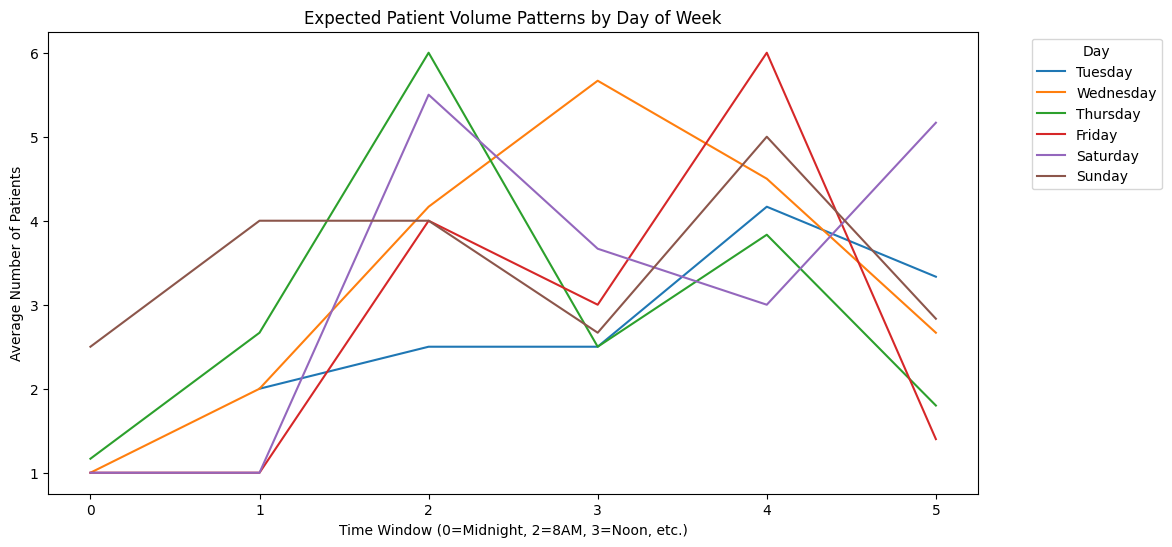

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def get_day_of_week_predictions(df_binned):
    """
    Predicts volume based on historical averages for each Day and Time Window.
    """
    # 1. Calculate the 'Normal' volume for every specific slot
    # e.g., What is the average volume for every 'Monday at Window 2'?
    baseline_model = df_binned.groupby(['day_of_week', 'time_window'])['total_volume'].agg([
        'mean', 'std', 'min', 'max'
    ]).reset_index()
    
    # Rename for clarity
    baseline_model.columns = ['day_of_week', 'time_window', 'avg_volume', 'vol_std', 'min_vol', 'max_vol']
    
    # 2. Map day numbers to Names for the console/frontend
    day_map = {0: 'Monday', 1: 'Tuesday', 2: 'Wednesday', 3: 'Thursday', 
               4: 'Friday', 5: 'Saturday', 6: 'Sunday'}
    baseline_model['day_name'] = baseline_model['day_of_week'].map(day_map)
    
    return baseline_model

# --- RUNNING THE ANALYSIS ---
predictions = get_day_of_week_predictions(data_binned)

# Example: See the predicted "Pattern" for a Monday
monday_pattern = predictions[predictions['day_name'] == 'Monday']
print("--- Predicted Volume Pattern for a Typical Monday ---")
print(monday_pattern[['time_window', 'avg_volume']])

# --- VISUALIZATION ---
plt.figure(figsize=(12, 6))
sns.lineplot(data=predictions, x='time_window', y='avg_volume', hue='day_name')
plt.title("Expected Patient Volume Patterns by Day of Week")
plt.xlabel("Time Window (0=Midnight, 2=8AM, 3=Noon, etc.)")
plt.ylabel("Average Number of Patients")
plt.legend(title='Day', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()